<a href="https://colab.research.google.com/github/overwatch093-alt/ADS1-Assignment1-Retail-EDA/blob/main/eda_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import seaborn as sns

# Load raw dataset
file_path = "3.retail_store_sales Assignment 1.csv"
raw_df = pd.read_csv(file_path)

print("=" * 60)
print("1. DATA DATASET SHAPE & TYPES AUDIT")
print("=" * 60)
print(f"Total Rows: {raw_df.shape[0]:,}")
print(f"Total Columns: {raw_df.shape[1]}")
print("\nData types per column:")
print(raw_df.dtypes)

print("\n" + "=" * 60)
print("2. MISSING VALUES AUDIT")
print("=" * 60)
missing_audit = pd.DataFrame({
    'Missing Count': raw_df.isnull().sum(),
    'Missing Percentage (%)': (raw_df.isnull().sum() / len(raw_df) * 100).round(2)
})
print(missing_audit[missing_audit['Missing Count'] > 0])

print("\n" + "=" * 60)
print("3. DUPLICATE ROWS AUDIT")
print("=" * 60)
print(f"Exact Duplicate Rows Count: {raw_df.duplicated().sum()}")
print(f"Duplicate Transaction ID Count: {raw_df['Transaction ID'].duplicated().sum()}")

print("\n" + "=" * 60)
print("4. HEAD PREVIEW (FIRST 5 ROWS)")
print("=" * 60)
display(raw_df.head())

1. DATA DATASET SHAPE & TYPES AUDIT
Total Rows: 12,575
Total Columns: 11

Data types per column:
Transaction ID       object
Customer ID          object
Category             object
Item                 object
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method       object
Location             object
Transaction Date     object
Discount Applied     object
dtype: object

2. MISSING VALUES AUDIT
                  Missing Count  Missing Percentage (%)
Item                       1213                    9.65
Price Per Unit              609                    4.84
Quantity                    604                    4.80
Total Spent                 604                    4.80
Discount Applied           4199                   33.39

3. DUPLICATE ROWS AUDIT
Exact Duplicate Rows Count: 0
Duplicate Transaction ID Count: 0

4. HEAD PREVIEW (FIRST 5 ROWS)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,8/4/2024,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,23/7/2023,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,5/10/2022,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,7/5/2022,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2/10/2022,False


In [10]:
# ==========================================
# STEP 2: DATA CLEANING & FEATURE ENGINEERING
# ==========================================

def clean_retail_data(df_raw: pd.DataFrame) -> pd.DataFrame:
    """
    Cleans raw retail transaction dataset by handling missing values,
    correcting data types, and engineering time features.
    """
    df_clean = df_raw.copy()

    # 1. Standardize and parse Transaction Date (DD/MM/YYYY)
    df_clean['Transaction Date'] = pd.to_datetime(
        df_clean['Transaction Date'], dayfirst=True, errors='coerce'
    )

    # Feature Engineering: Extract Year and Year-Month
    df_clean['Year'] = df_clean['Transaction Date'].dt.year
    df_clean['YearMonth'] = df_clean['Transaction Date'].dt.to_period('M')

    # 2. Impute missing Price Per Unit using formula: Total Spent / Quantity
    price_missing_mask = (
        df_clean['Price Per Unit'].isnull() &
        df_clean['Total Spent'].notnull() &
        df_clean['Quantity'].notnull()
    )
    df_clean.loc[price_missing_mask, 'Price Per Unit'] = (
        df_clean.loc[price_missing_mask, 'Total Spent'] / df_clean.loc[price_missing_mask, 'Quantity']
    )

    # 3. Handle missing boolean values for Discount Applied
    df_clean['Discount Applied'] = (
        df_clean['Discount Applied'].infer_objects(copy=False).fillna(False).astype(bool)
    )

    # 4. Fill missing Item names
    df_clean['Item'] = df_clean['Item'].fillna("Unspecified Item")

    # 5. Drop remaining rows where primary target Total Spent is unrecoverable
    df_clean = df_clean.dropna(subset=['Total Spent']).copy()

    return df_clean

# Run cleaning function
cleaned_df = clean_retail_data(raw_df)

print("Data Cleaning Completed!")
print(f"Cleaned Dataset Shape: {cleaned_df.shape}")
print("\nRemaining Missing Values Check:")
print(cleaned_df.isnull().sum())

Data Cleaning Completed!
Cleaned Dataset Shape: (11971, 13)

Remaining Missing Values Check:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
Year                0
YearMonth           0
dtype: int64


/tmp/ipykernel_739/3511486420.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean['Discount Applied'].infer_objects(copy=False).fillna(False).astype(bool)


In [11]:
# =============================================================================
# STEP 3: DESCRIPTIVE STATISTICS & MULTIDIMENSIONAL EDA
# =============================================================================

def perform_descriptive_stats(df: pd.DataFrame) -> None:
    """
    Computes summary statistics, evaluates catalogue/SKU mapping integrity,
    analyzes omnichannel revenue parity and payment dynamics, and audits
    temporal boundaries and account cardinality.
    """
    print("=" * 75)
    print("1. NUMERICAL DESCRIPTIVE STATISTICS & PROMOTIONAL AUDIT")
    print("=" * 75)
    num_cols = ['Price Per Unit', 'Quantity', 'Total Spent']
    print("\n--- Summary Statistics (Parametric & Quantiles) ---")
    display(df[num_cols].describe().round(2))

    print("\n--- Feature Pearson Correlation Matrix ---")
    display(df[num_cols].corr().round(3))

    print("\n--- Promotional Impact Comparison (Discount Applied True vs. False) ---")
    discount_perf = df.groupby('Discount Applied')['Total Spent'].agg(
        Orders='count', Total_Revenue='sum', Mean_Spend='mean', Median_Spend='median'
    )
    display(discount_perf.round(2))

    print("\n" + "=" * 75)
    print("2. CATEGORY, SKU & CATALOGUE INTEGRITY AUDIT")
    print("=" * 75)
    cat_summary = (
        df.groupby('Category')['Total Spent']
        .agg(Transactions='count', Total_Revenue='sum', Mean_Spent='mean')
        .reset_index()
        .sort_values(by='Total_Revenue', ascending=False)
    )
    display(cat_summary.round(2))

    # SKU 1-to-1 Mapping Check & Unspecified Item Preserved Revenue
    unspecified_mask = df['Item'] == "Unspecified Item"
    known_items = df[~unspecified_mask]
    mapping_uniqueness = known_items.groupby(['Category', 'Price Per Unit'])['Item'].nunique().max()
    unspecified_rev = df.loc[unspecified_mask, 'Total Spent'].sum()
    unspecified_cnt = unspecified_mask.sum()
    print(f"\nSKU Catalogue Mapping Integrity : {mapping_uniqueness} unique item per (Category, Price Per Unit)")
    print(f"Unspecified SKU Preserved Volume: {unspecified_cnt:,} orders | ${unspecified_rev:,.2f} valid revenue")

    print("\n" + "=" * 75)
    print("3. OMNICHANNEL & PAYMENT DISTRIBUTION DYNAMICS")
    print("=" * 75)
    # Overall Channel Revenue Parity
    loc_summary = df.groupby('Location')['Total Spent'].agg(
        Total_Revenue='sum', Transactions='count', Mean_Spend='mean', Median_Spend='median'
    )
    loc_summary['Revenue_Share (%)'] = (loc_summary['Total_Revenue'] / loc_summary['Total_Revenue'].sum() * 100).round(2)
    print("--- Omnichannel Revenue & Volume Parity (50/50 Split) ---")
    display(loc_summary)

    print("\n--- Channel vs. Payment Method Crosstab (Order Counts) ---")
    display(pd.crosstab(df['Location'], df['Payment Method'], margins=True))

    print("\n--- Channel vs. Payment Method Crosstab (Revenue in $) ---")
    display(pd.crosstab(df['Location'], df['Payment Method'], values=df['Total Spent'], aggfunc='sum', margins=True).round(2))

    print("\n--- Payment Method Distribution (Tukey 1.5xIQR & Outlier Fence) ---")
    payment_stats = df.groupby('Payment Method')['Total Spent'].agg(
        Orders='count',
        Mean='mean',
        Std='std',
        Min='min',
        Q1=lambda x: x.quantile(0.25),
        Median='median',
        Q3=lambda x: x.quantile(0.75),
        Max='max'
    )
    payment_stats['IQR'] = payment_stats['Q3'] - payment_stats['Q1']
    payment_stats['Upper_Fence'] = payment_stats['Q3'] + 1.5 * payment_stats['IQR']
    display(payment_stats.round(2))

    print("\n" + "=" * 75)
    print("4. LONGITUDINAL TRENDS & CUSTOMER CARDINALITY AUDIT")
    print("=" * 75)
    start_date = df['Transaction Date'].min().strftime('%d/%m/%Y')
    end_date = df['Transaction Date'].max().strftime('%d/%m/%Y')
    print(f"Dataset Window Boundaries: {start_date} to {end_date} (Audited cutoff on 18/01/2025)")

    monthly_rev = df.groupby(df['Transaction Date'].dt.to_period('M'))['Total Spent'].sum()
    print("\nTop 5 Peak Revenue Months:")
    display(monthly_rev.sort_values(ascending=False).head(5))
    print(f"\nIncomplete Month (2025-01): ${monthly_rev.loc['2025-01']:,.2f} ({len(df[df['Year'] == 2025])} transactions)")

    print("\n--- Customer ID Account Distribution Summary (N = 25) ---")
    cust_summary = df.groupby('Customer ID')['Total Spent'].agg(
        Transactions='count', Total_Spent='sum', Mean_Order='mean'
    )
    display(cust_summary.describe().round(2))

# Execute comprehensive descriptive statistics
perform_descriptive_stats(cleaned_df)

1. NUMERICAL DESCRIPTIVE STATISTICS & PROMOTIONAL AUDIT

--- Summary Statistics (Parametric & Quantiles) ---


,Price Per Unit,Quantity,Total Spent
count,11971.00,11971.00,11971.00
mean,23.36,5.54,129.65
std,10.74,2.86,94.75
min,5.00,1.00,5.00
25%,14.00,3.00,51.00
50%,23.00,6.00,108.50
75%,33.50,8.00,192.00
max,41.00,10.00,410.00



--- Feature Pearson Correlation Matrix ---


,Price Per Unit,Quantity,Total Spent
Price Per Unit,1.000,0.010,0.631
Quantity,0.010,1.000,0.712
Total Spent,0.631,0.712,1.000



--- Promotional Impact Comparison (Discount Applied True vs. False) ---


...

,Orders,Mean,Std,Min,Q1,Median,Q3,Max,IQR,Upper_Fence
Payment Method,,,,,,,,,,
Cash,4103,131.05,94.78,5.0,52.0,109.5,192.5,410.0,140.5,403.25
Credit Card,3927,129.13,95.23,5.0,51.0,108.5,192.0,410.0,141.0,403.50
Digital Wallet,3941,128.72,94.25,5.0,50.0,107.5,190.0,410.0,140.0,400.00



4. LONGITUDINAL TRENDS & CUSTOMER CARDINALITY AUDIT
Dataset Window Boundaries: 01/01/2022 to 18/01/2025 (Audited cutoff on 18/01/2025)

Top 5 Peak Revenue Months:


,Total Spent
Transaction Date,
2022-01,52911.5
2024-12,48466.5
2023-01,48052.5
2024-01,47908.5
2024-04,46271.0



Incomplete Month (2025-01): $25,548.50 (202 transactions)

--- Customer ID Account Distribution Summary (N = 25) ---


,Transactions,Total_Spent,Mean_Order
count,25.00,25.00,25.00
mean,478.84,62082.84,129.69
std,20.71,2933.82,3.82
min,446.00,57155.50,121.10
25%,461.00,60694.50,127.01
50%,478.00,61533.00,129.89
75%,494.00,63155.50,132.73
max,519.00,68452.00,136.35


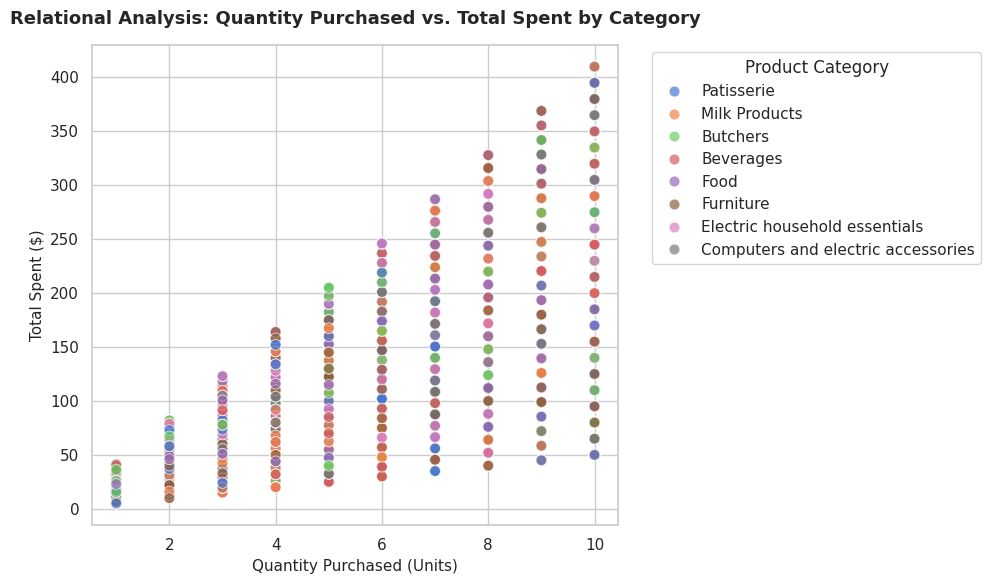

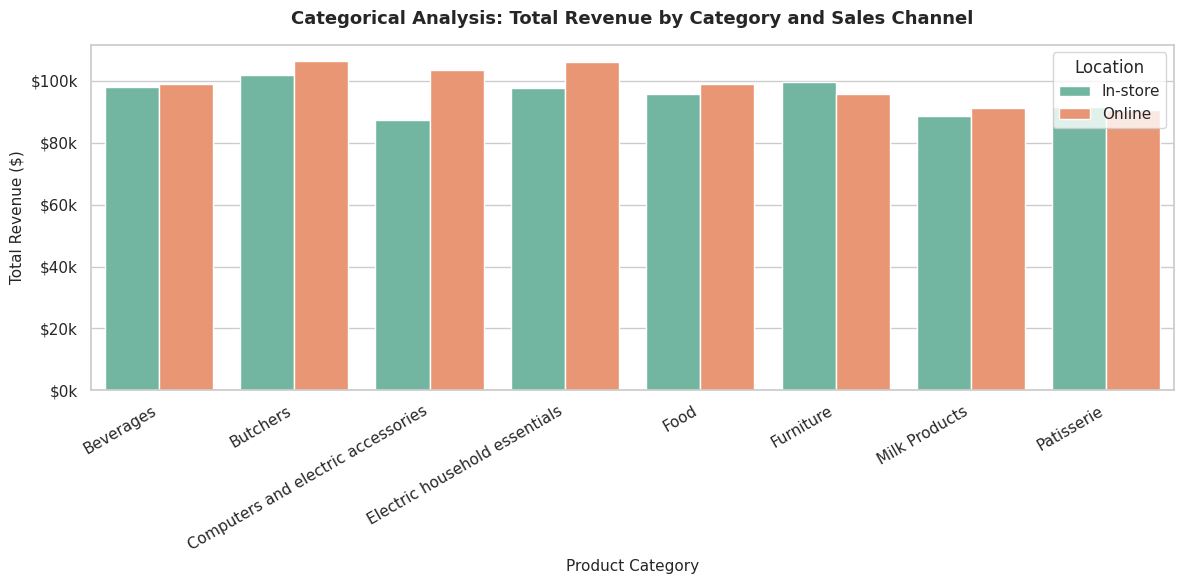

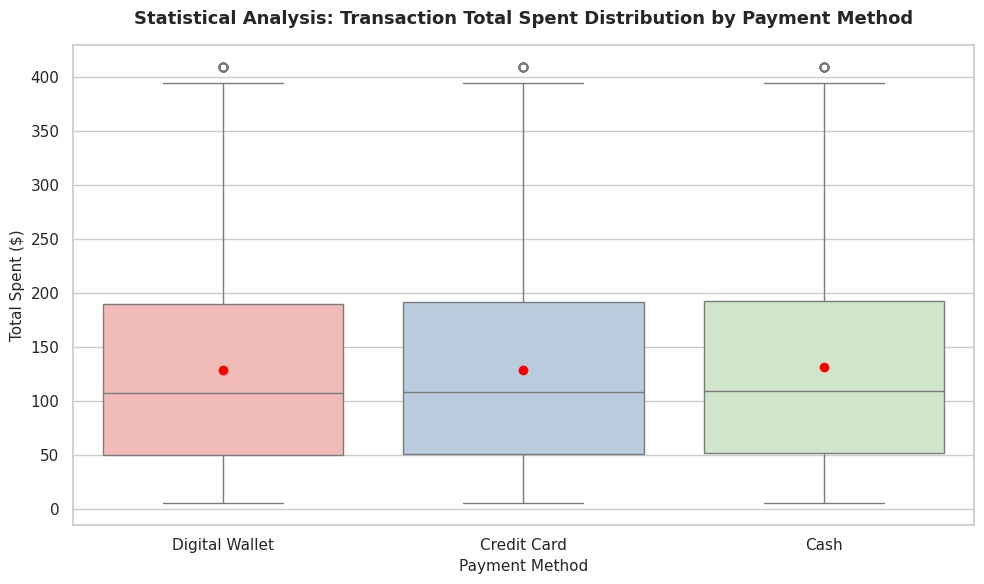

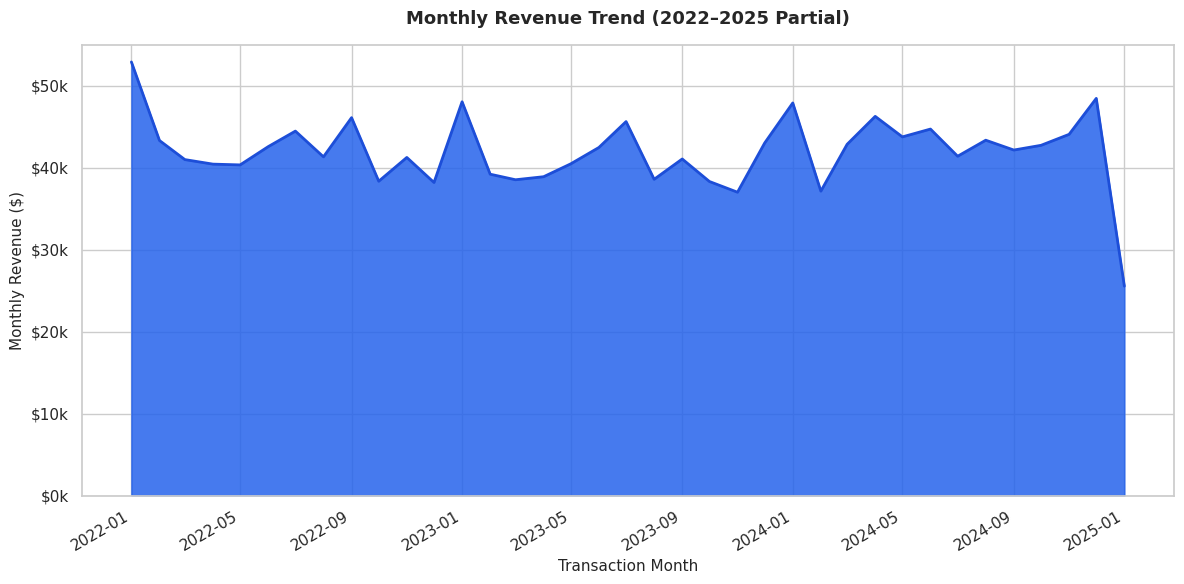

In [9]:
# =============================================================================
# STEP 4: DEDICATED VISUALISATION FUNCTIONS (ONE FUNCTION PER PLOT)
# =============================================================================

def generate_relational_plot(df: pd.DataFrame, output_name: str = "relational_plot.png") -> None:
    """Plot Type 1: Scatter plot analyzing Quantity vs. Total Spent by Category."""
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.scatterplot(
        data=df,
        x="Quantity",
        y="Total Spent",
        hue="Category",
        alpha=0.7,
        s=60,
        ax=ax
    )
    ax.set_title("Relational Analysis: Quantity Purchased vs. Total Spent by Category", fontsize=13, fontweight="bold", pad=15)
    ax.set_xlabel("Quantity Purchased (Units)", fontsize=11)
    ax.set_ylabel("Total Spent ($)", fontsize=11)
    ax.legend(title="Product Category", bbox_to_anchor=(1.05, 1), loc="upper left")

    fig.tight_layout()
    fig.savefig(output_name, dpi=300)
    plt.show()
    plt.close(fig)


def generate_categorical_plot(df: pd.DataFrame, output_name: str = "categorical_plot.png") -> None:
    """Plot Type 2: Grouped bar chart comparing Revenue across Categories and Sales Channels."""
    fig, ax = plt.subplots(figsize=(12, 6))
    cat_sales = df.groupby(["Category", "Location"])["Total Spent"].sum().reset_index()

    sns.barplot(
        data=cat_sales,
        x="Category",
        y="Total Spent",
        hue="Location",
        palette="Set2",
        ax=ax
    )
    ax.set_title("Categorical Analysis: Total Revenue by Category and Sales Channel", fontsize=13, fontweight="bold", pad=15)
    ax.set_xlabel("Product Category", fontsize=11)
    ax.set_ylabel("Total Revenue ($)", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"${val*1e-3:,.0f}k"))
    plt.xticks(rotation=30, ha="right")

    fig.tight_layout()
    fig.savefig(output_name, dpi=300)
    plt.show()
    plt.close(fig)


def generate_statistical_plot(df: pd.DataFrame, output_name: str = "statistical_plot.png") -> None:
    """Plot Type 3: Boxplot illustrating spending distributions across Payment Methods."""
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(
        data=df,
        x="Payment Method",
        y="Total Spent",
        hue="Payment Method",
        palette="Pastel1",
        legend=False,
        showmeans=True,
        meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "red"},
        ax=ax
    )
    ax.set_title("Statistical Analysis: Transaction Total Spent Distribution by Payment Method", fontsize=13, fontweight="bold", pad=15)
    ax.set_xlabel("Payment Method", fontsize=11)
    ax.set_ylabel("Total Spent ($)", fontsize=11)

    fig.tight_layout()
    fig.savefig(output_name, dpi=300)
    plt.show()
    plt.close(fig)


def generate_timeseries_plot(df: pd.DataFrame, output_name: str = "timeseries_plot.png") -> None:
    """Plot Type 4: Area chart tracking monthly cleaned revenue trend over time."""
    temp_df = df.copy()
    if not pd.api.types.is_datetime64_any_dtype(temp_df["Transaction Date"]):
        temp_df["Transaction Date"] = pd.to_datetime(temp_df["Transaction Date"], dayfirst=True, errors="coerce")

    monthly_revenue = temp_df.groupby(temp_df["Transaction Date"].dt.to_period("M"))["Total Spent"].sum().reset_index()
    monthly_revenue["Date"] = monthly_revenue["Transaction Date"].dt.to_timestamp()

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.fill_between(monthly_revenue["Date"], monthly_revenue["Total Spent"], color="#2563eb", alpha=0.85)
    ax.plot(monthly_revenue["Date"], monthly_revenue["Total Spent"], color="#1d4ed8", linewidth=2)

    ax.set_title("Monthly Revenue Trend (2022–2025 Partial)", fontsize=13, fontweight="bold", pad=15)
    ax.set_xlabel("Transaction Month", fontsize=11)
    ax.set_ylabel("Monthly Revenue ($)", fontsize=11)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda val, pos: f"${val*1e-3:,.0f}k"))
    ax.set_ylim(0, 55000)

    fig.autofmt_xdate(rotation=30, ha="right")
    fig.tight_layout()
    fig.savefig(output_name, dpi=300)
    plt.show()
    plt.close(fig)


# Run all plotting functions
generate_relational_plot(cleaned_df)
generate_categorical_plot(cleaned_df)
generate_statistical_plot(cleaned_df)
generate_timeseries_plot(cleaned_df)